# ANALYSIS of the GALLOCANTA dataset using QIIME2 and DADA2 (10/02/23)

# AMPLICON-TARGETED SEQUENCING

In [ ]:
# Set the working directory

cd /data


In [ ]:
# To activate QIIME2 environment, use:

source activate qiime2-2022.11

# 0) Importing files

In [ ]:
# Imported emp-paired-end-sequences as EMPPairedEndDirFmt to gallocanta-sequences.qza (6.0 Gb)

qiime tools import --type EMPPairedEndSequences \
                --input-path emp-paired-end-sequences \
                --output-path gallocanta-sequences.qza

# Ok

In [ ]:
# Check import

qiime tools peek gallocanta-sequences.qza

UUID:        cb1a7fbd-a1b8-4bfa-8d29-1676365a9ae7
Type:        EMPPairedEndSequences
Data format: EMPPairedEndDirFmt

# Ok

# 1) Demultiplexing

In [ ]:
# First, we have to resolve the barcodes for each sequence to assign samples (demultiplex) and to put all this into the metadata file...
# Barcodes provided by sequencing facilities (UPV) and decomposed in Adapter+Barcode+Pad+Linker+FWDPrimer

Pos. Plate1	Row	Col	Code	Sequence(5'-3')	Illumina_adapter	Golay_barcode(12nt)	Primer_pad	Primer_linker	515F primer
A1	A	1	515rcbc0	AATGATACGGCGACCACCGAGATCTACACGCTAGCCTTCGTCGCTATGGTAATTGTGTGYCAGCMGCCGCGGTAA	AATGATACGGCGACCACCGAGATCTACACGCT	AGCCTTCGTCGC	TATGGTAATT	GT	GTGYCAGCMGCCGCGGTAA
B1	B	1	515rcbc12	AATGATACGGCGACCACCGAGATCTACACGCTCGTATAAATGCGTATGGTAATTGTGTGYCAGCMGCCGCGGTAA	AATGATACGGCGACCACCGAGATCTACACGCT	CGTATAAATGCG	TATGGTAATT	GT	GTGYCAGCMGCCGCGGTAA
C1	C	1	515rcbc24	AATGATACGGCGACCACCGAGATCTACACGCTTGACTAATGGCCTATGGTAATTGTGTGYCAGCMGCCGCGGTAA	AATGATACGGCGACCACCGAGATCTACACGCT	TGACTAATGGCC	TATGGTAATT	GT	GTGYCAGCMGCCGCGGTAA
D1	D	1	515rcbc36	AATGATACGGCGACCACCGAGATCTACACGCTGTGGAGTCTCATTATGGTAATTGTGTGYCAGCMGCCGCGGTAA	AATGATACGGCGACCACCGAGATCTACACGCT	GTGGAGTCTCAT	TATGGTAATT	GT	GTGYCAGCMGCCGCGGTAA

In [ ]:
# metadata file (first rows):

#SampleID	BarcodeSequence	LinkerPrimerSequence	Well	Plate	Experiment	CorePlot	DepthTime	Replicate
#q2:types	categorical	categorical	categorical	categorical	categorical	categorical	categorical	categorical
C1F1.1	AGCCTTCGTCGC	GTGYCAGCMGCCGCGGTAA	A1	DNA	Cores	C1	F1	1
C1F1.2	CGTATAAATGCG	GTGYCAGCMGCCGCGGTAA	B1	DNA	Cores	C1	F1	2
C1F1.3	TGACTAATGGCC	GTGYCAGCMGCCGCGGTAA	C1	DNA	Cores	C1	F1	3
C1F2.1	GTGGAGTCTCAT	GTGYCAGCMGCCGCGGTAA	D1	DNA	Cores	C1	F2	1
C1F2.2	TGATGTGCTAAG	GTGYCAGCMGCCGCGGTAA	E1	DNA	Cores	C1	F2	2
C1F2.3	TGTGCACGCCAT	GTGYCAGCMGCCGCGGTAA	F1	DNA	Cores	C1	F2	3
C1F3.1	GGTGAGCAAGCA	GTGYCAGCMGCCGCGGTAA	G1	DNA	Cores	C1	F3	1
C1F3.2	CTATGTATTAGT	GTGYCAGCMGCCGCGGTAA	H1	DNA	Cores	C1	F3	2
C1F3.3	TCCATACCGGAA	GTGYCAGCMGCCGCGGTAA	A2	DNA	Cores	C1	F3	3
C1F4.1	ATGCTGCAACAC	GTGYCAGCMGCCGCGGTAA	B2	DNA	Cores	C1	F4	1
C1F4.2	CGGGACACCCGA	GTGYCAGCMGCCGCGGTAA	C2	DNA	Cores	C1	F4	2
C1F4.3	ACCTTACACCTT	GTGYCAGCMGCCGCGGTAA	D2	DNA	Cores	C1	F4	3
C1F5.1	GTAGTAGACCAT	GTGYCAGCMGCCGCGGTAA	E2	DNA	Cores	C1	F5	1
C1F5.2	CCGGACAAGAAG	GTGYCAGCMGCCGCGGTAA	F2	DNA	Cores	C1	F5	2
C2F1.1	TAAATATACCCT	GTGYCAGCMGCCGCGGTAA	G2	DNA	Cores	C2	F1	1
C2F1.2	ACTCCCGTGTGA	GTGYCAGCMGCCGCGGTAA	H2	DNA	Cores	C2	F1	2
C2F1.3	AGCCCTGCTACA	GTGYCAGCMGCCGCGGTAA	A3	DNA	Cores	C2	F1	3
C2F2.1	ACTCGCTCGCTG	GTGYCAGCMGCCGCGGTAA	B3	DNA	Cores	C2	F2	1
C2F2.2	CTGTCTATACTA	GTGYCAGCMGCCGCGGTAA	C3	DNA	Cores	C2	F2	2
C2F2.3	TAATCTCGCCGG	GTGYCAGCMGCCGCGGTAA	D3	DNA	Cores	C2	F2	3
C2F3.1	AGTAAAGATCGT	GTGYCAGCMGCCGCGGTAA	E3	DNA	Cores	C2	F3	1
C2F3.2	TTGCTGGACGCT	GTGYCAGCMGCCGCGGTAA	F3	DNA	Cores	C2	F3	2
C2F3.3	TTGCGGACCCTA	GTGYCAGCMGCCGCGGTAA	G3	DNA	Cores	C2	F3	3
C2F4.2	CGGTATAGCAAT	GTGYCAGCMGCCGCGGTAA	H3	DNA	Cores	C2	F4	2
C3F1.1	CCTAACGGTCCA	GTGYCAGCMGCCGCGGTAA	A4	DNA	Cores	C3	F1	1
C3F1.2	TTCCTTAGTAGT	GTGYCAGCMGCCGCGGTAA	B4	DNA	Cores	C3	F1	2
C3F1.3	TATGCCAGAGAT	GTGYCAGCMGCCGCGGTAA	C4	DNA	Cores	C3	F1	3
C3F2.1	ATCTAGTGGCAA	GTGYCAGCMGCCGCGGTAA	D4	DNA	Cores	C3	F2	1


# you can validate your metadata file using an add-on on Google sheets called Keemei (https://keemei.qiime2.org/)


In [ ]:
# Demultiplexing

qiime demux emp-paired --i-seqs gallocanta-sequences.qza \
                        --m-barcodes-file gallocanta_metadata.tsv \
                        --m-barcodes-column BarcodeSequence \
                        --p-no-golay-error-correction \
                        --o-per-sample-sequences gallocanta_demux.qza \
                        --o-error-correction-details demux-details.qza

>Saved SampleData[PairedEndSequencesWithQuality] to: gallocanta_demux.qza
>Saved ErrorCorrectionDetails to: demux-details.qza

# Demultiplexing is OK using no-golay-error correction

In [ ]:
# Summary

qiime demux summarize \
  --i-data gallocanta_demux.qza \
  --o-visualization gallocanta_demux.qzv

>Saved Visualization to: gallocanta_demux.qzv

# Visualization

qiime tools view gallocanta_demux.qzv

# ok

In [ ]:
# Export demux qza to fastq files

qiime tools export \
--input-path gallocanta_demux.qza \
--output-path exported-fastq


# 2) Denoising & DADA2

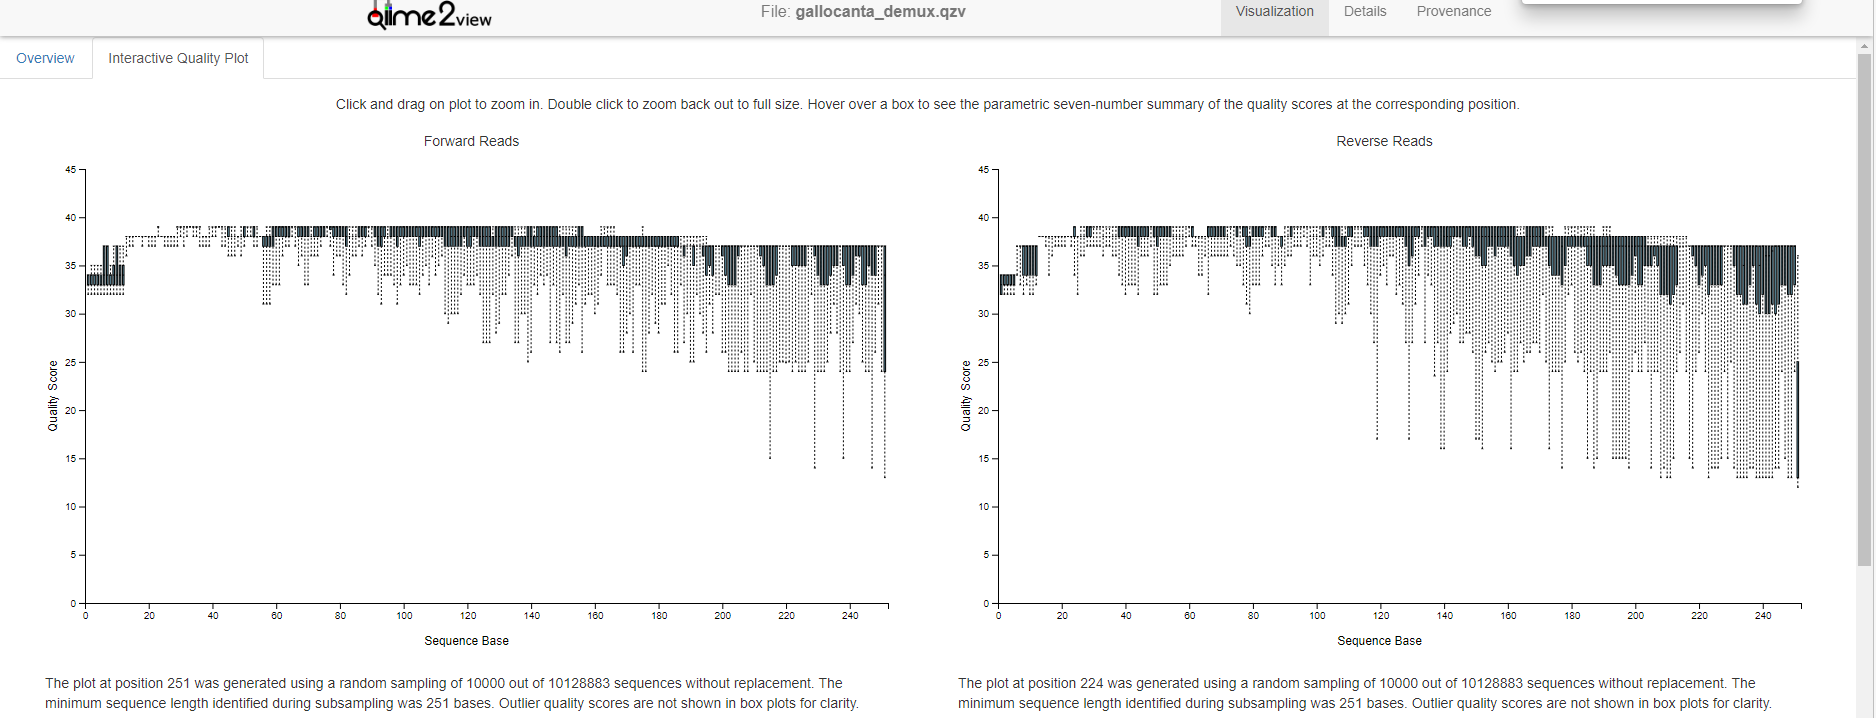

In [ ]:
qiime dada2 denoise-paired \
    --i-demultiplexed-seqs gallocanta_demux.qza \
    --p-trim-left-f 5 \
    --p-trim-left-r 5 \
    --p-trunc-len-f 249 \
    --p-trunc-len-r 215 \
    --p-trunc-q 2 \
    --p-n-threads 2 \
    --o-table gallocanta_asvtable.qza \
    --o-representative-sequences gallocanta_rep-seqs.qza \
    --o-denoising-stats gallocanta_denoising_stats.qza


>Saved FeatureTable[Frequency] to: gallocanta_asvtable.qza
>Saved FeatureData[Sequence] to: gallocanta_rep-seqs.qza
>Saved SampleData[DADA2Stats] to: gallocanta_denoising_stats.qza

In [ ]:
# Summary

qiime feature-table summarize \
    --i-table gallocanta_asvtable.qza \
    --o-visualization gallocanta_asvtable.qzv \
    --m-sample-metadata-file gallocanta_metadata.tsv   

>Saved Visualization to: gallocanta_asvtable.qzv

# Visualization

qiime tools view gallocanta_asvtable.qzv 

# 19,630 features (ASVs), 125 samples (including the NTC), 8,196,644 seqs

In [ ]:
# Check DENOISING 

qiime metadata tabulate \
    --m-input-file gallocanta_denoising_stats.qza \
    --o-visualization gallocanta_denoising_stats.qzv

>Saved Visualization to: gallocanta_denoising_stats.qzv
    
qiime tools view gallocanta_denoising_stats.qzv

69-90% of the input seqs resulted to be non-chimeric. Min reads samples C4F5.3: 58 (54%), cC1F1.2: 925 (49%), cC1F1.3: 1417 (79%), cR9T1: 1617 (83%), C5F5.2: 1764 (33%); max reads sample cC3F1.3: 214,492 (85%). NTC 2074 seqs (79%).

In [ ]:
# Generate tabular view of feature identifier to sequence mapping

qiime feature-table tabulate-seqs \
    --i-data gallocanta_rep-seqs.qza \
    --o-visualization gallocanta_rep-seqs.qzv

>Saved Visualization to: gallocanta_rep-seqs.qzv
    
qiime tools view gallocanta_rep-seqs.qzv


## Filter out NTC from asv table and rep-seqs

In [ ]:
qiime feature-table filter-samples \
    --i-table gallocanta_asvtable.qza \
    --m-metadata-file gallocanta_metadata.tsv \
    --p-where "[Experiment]='NTC'" \
    --p-exclude-ids \
    --o-filtered-table gallocanta_asvtable-NO-NTC.qza

>Saved FeatureTable[Frequency] to: gallocanta_asvtable-NO-NTC.qza

qiime feature-table filter-seqs \
    --i-data gallocanta_rep-seqs.qza \
    --i-table gallocanta_asvtable-NO-NTC.qza \
    --o-filtered-data gallocanta_rep-seqs-NO-NTC.qza

>Saved FeatureData[Sequence] to: gallocanta_rep-seqs-NO-NTC.qza

In [ ]:
# Summary

qiime feature-table summarize \
    --i-table gallocanta_asvtable-NO-NTC.qza \
    --o-visualization gallocanta_asvtable-NO-NTC.qzv \
    --m-sample-metadata-file gallocanta_metadata.tsv   

>Saved Visualization to: gallocanta_asvtable-NO-NTC.qzv

# Visualization

qiime tools view gallocanta_asvtable-NO-NTC.qzv 

# 19,621 features (ASVs), 124 samples (NO NTC), 8,194,570 seqs

In [ ]:
# Generate tabular view of feature identifier to sequence mapping

qiime feature-table tabulate-seqs \
    --i-data gallocanta_rep-seqs-NO-NTC.qza \
    --o-visualization gallocanta_rep-seqs-NO-NTC.qzv

>Saved Visualization to: gallocanta_rep-seqs-NO-NTC.qzv
    
qiime tools view gallocanta_rep-seqs-NO-NTC.qzv

# you can download a fasta file from the .qzv

## Filter the asv table and rep-seqs to split Cores and Rewetting samples

## Cores

In [ ]:
qiime feature-table filter-samples \
    --i-table gallocanta_asvtable-NO-NTC.qza \
    --m-metadata-file gallocanta_metadata.tsv \
    --p-where "[Experiment]='Cores'" \
    --o-filtered-table gallocanta_cores_asvtable.qza

# ok

In [ ]:
# Summary

qiime feature-table summarize \
    --i-table gallocanta_cores_asvtable.qza \
    --o-visualization gallocanta_cores_asvtable.qzv \
    --m-sample-metadata-file gallocanta_metadata.tsv   

# Visualization

qiime tools view gallocanta_cores_asvtable.qzv 

# 14,903 features (ASVs), 77 samples, 4,378,563 seqs

In [ ]:
# export filtered ASV table (qza to biom format and then to tsv format)

qiime tools export \
  --input-path gallocanta_cores_asvtable.qza \
  --output-path exported-files/gallocanta_cores_asvtable


biom convert -i exported-files/gallocanta_cores_asvtable/feature-table.biom \
                -o exported-files/gallocanta_cores_asvtable/gallocanta_cores_asvtable.tsv \
                --to-tsv


In [ ]:
# FILTER OUT the ASVs from the repseq file that are not in the new filtered table

qiime feature-table filter-seqs \
    --i-data gallocanta_rep-seqs-NO-NTC.qza \
    --i-table gallocanta_cores_asvtable.qza \
    --o-filtered-data  gallocanta_cores_rep-seqs.qza


In [ ]:
# Generate tabular view of feature identifier to sequence mapping

qiime feature-table tabulate-seqs \
    --i-data gallocanta_cores_rep-seqs.qza \
    --o-visualization gallocanta_cores_rep-seqs.qzv

    
qiime tools view gallocanta_cores_rep-seqs.qzv

# you can download a fasta file from the .qzv

## Rewetting

In [ ]:
qiime feature-table filter-samples \
    --i-table gallocanta_asvtable-NO-NTC.qza \
    --m-metadata-file gallocanta_metadata.tsv \
    --p-where "[Experiment]='Rewetting'" \
    --o-filtered-table gallocanta_rewetting_asvtable.qza

# ok

In [ ]:
# Summary

qiime feature-table summarize \
    --i-table gallocanta_rewetting_asvtable.qza \
    --o-visualization gallocanta_rewetting_asvtable.qzv \
    --m-sample-metadata-file gallocanta_metadata.tsv   

# Visualization

qiime tools view gallocanta_rewetting_asvtable.qzv 

# 6,499 features (ASVs), 47 samples, 3,816,007 seqs

In [ ]:
# export filtered ASV table (qza to biom format and then to tsv format)

qiime tools export \
  --input-path gallocanta_rewetting_asvtable.qza \
  --output-path exported-files/gallocanta_rewetting_asvtable


biom convert -i exported-files/gallocanta_rewetting_asvtable/feature-table.biom \
                -o exported-files/gallocanta_rewetting_asvtable/gallocanta_rewetting_asvtable.tsv \
                --to-tsv


In [ ]:
# FILTER OUT the ASVs from the repseq file that are not in the new filtered table

qiime feature-table filter-seqs \
    --i-data gallocanta_rep-seqs-NO-NTC.qza \
    --i-table gallocanta_rewetting_asvtable.qza \
    --o-filtered-data  gallocanta_rewetting_rep-seqs.qza


In [ ]:
# Generate tabular view of feature identifier to sequence mapping

qiime feature-table tabulate-seqs \
    --i-data  gallocanta_rewetting_rep-seqs.qza \
    --o-visualization  gallocanta_rewetting_rep-seqs.qzv

    
qiime tools view  gallocanta_rewetting_rep-seqs.qzv

# you can download a fasta file from the .qzv

# 3) Taxonomy Assignments

## CORES

In [ ]:
# Using the new pre-trained Naive Bayes classifier: Silva 138 99% OTUs from 515F/806R region of sequences
# downloaded from https://docs.qiime2.org/2022.11/data-resources/ Use the same version of the classifier as the qiime installed

qiime feature-classifier classify-sklearn \
  --i-classifier Taxonomy/silva-138-99-515-806-nb-classifier_2020.8.qza \
  --i-reads gallocanta_cores_rep-seqs.qza \
  --o-classification Taxonomy/gallocanta_cores_tax_silva138.qza

# 3h-runtime

# Visualization

qiime metadata tabulate \
    --m-input-file Taxonomy/gallocanta_cores_tax_silva138.qza \
    --o-visualization Taxonomy/gallocanta_cores_tax_silva138.qzv

    
qiime tools view Taxonomy/gallocanta_cores_tax_silva138.qzv

# we download the file, upload it in excel and make some edits

## REWETTING

In [ ]:
# Using the new pre-trained Naive Bayes classifier: Silva 138 99% OTUs from 515F/806R region of sequences
# downloaded from https://docs.qiime2.org/2020.8/data-resources/ Use the same version of the classifier as the qiime installed

qiime feature-classifier classify-sklearn \
  --i-classifier Taxonomy/silva-138-99-515-806-nb-classifier_2020.8.qza \
  --i-reads gallocanta_rewetting_rep-seqs.qza \
  --o-classification Taxonomy/gallocanta_rewetting_tax_silva138.qza

# 1.4h-runtime

# Visualization

qiime metadata tabulate \
    --m-input-file Taxonomy/gallocanta_rewetting_tax_silva138.qza \
    --o-visualization Taxonomy/gallocanta_rewetting_tax_silva138.qzv

    
qiime tools view Taxonomy/gallocanta_rewetting_tax_silva138.qzv

# we download the file, upload it in excel and make some edits

# 4) Alignment and Phylogeny

In [ ]:
# CORES
screen
qiime phylogeny align-to-tree-mafft-fasttree \
    --i-sequences gallocanta_cores_rep-seqs.qza \
    --output-dir gallocanta_cores_align2tree \
    --p-n-threads 2
exit

#20 min-runtime

# REWETTING
screen
qiime phylogeny align-to-tree-mafft-fasttree \
    --i-sequences gallocanta_rewetting_rep-seqs.qza \
    --output-dir gallocanta_rewetting_align2tree \
    --p-n-threads 2
exit

#10 min-runtime